# NYC Yellow Taxi Trip & Revenue Analytics

## Project Overview

This project analyses NYC Yellow Taxi trip records from January 2024
to explore passenger pickup patterns, journey distances, trip durations,
and operational performance.

### Business Objectives
1. Identify peak taxi pickup hours.
2. Compare weekday and weekend travel patterns.
3. Analyse trip duration and distance.
4. Investigate differences across pickup and drop-off locations.
5. Develop data-driven operational recommendations.

### Tools
- Python
- Pandas
- Matplotlib
- SQL (upcoming)
- Power BI (upcoming)

### Data Source
NYC Taxi and Limousine Commission — Yellow Taxi Trip Records.

In [64]:

# Import libraries
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


## 1. Data Loading and Initial Exploration

In this section, we load the January 2024 NYC Yellow Taxi trip data and examine its structure, columns and data types before cleaning.

In [65]:

# Locate the project folder
project_folder = Path.cwd()

# Support running from the project root or Notebook folder
if project_folder.name.lower() in ("notebook", "notebooks"):
    project_folder = project_folder.parent

# Define the data folder
data_folder = project_folder / "Data"

# Load the January 2024 Yellow Taxi data
taxi_path = data_folder / "yellow_tripdata_2024-01.parquet"

df = pd.read_parquet(taxi_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Dataset loaded successfully!
Rows: 2964624
Columns: 19


In [66]:

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 2964624
Columns: 19


In [67]:

df.head()


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [68]:

# Display all column names
print(df.columns.tolist())


['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee']


In [69]:

# Examine the dataset structure
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [70]:

# Calculate trip duration in minutes
df["trip_duration_min"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Display the first five trip durations
df[["tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_duration_min"]].head()


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_min
0,2024-01-01 00:57:55,2024-01-01 01:17:43,19.800000
1,2024-01-01 00:03:00,2024-01-01 00:09:36,6.600000
2,2024-01-01 00:17:06,2024-01-01 00:35:01,17.916667
3,2024-01-01 00:36:38,2024-01-01 00:44:56,8.300000
4,2024-01-01 00:46:51,2024-01-01 00:52:57,6.100000



## 2. Data Quality Assessment

This section examines missing values, invalid trip durations, unusual trip distances, and fare anomalies to identify potential data quality issues before analysis.


In [71]:

# Count missing values in every column
missing_values = df.isnull().sum()

# Display the results
print(missing_values)


VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          140162
trip_distance                 0
RatecodeID               140162
store_and_fwd_flag       140162
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     140162
Airport_fee              140162
trip_duration_min             0
dtype: int64


In [72]:

# Calculate missing values as a percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display percentages rounded to 2 decimal places
print(missing_percentage.round(2))


VendorID                 0.00
tpep_pickup_datetime     0.00
tpep_dropoff_datetime    0.00
passenger_count          4.73
trip_distance            0.00
RatecodeID               4.73
store_and_fwd_flag       4.73
PULocationID             0.00
DOLocationID             0.00
payment_type             0.00
fare_amount              0.00
extra                    0.00
mta_tax                  0.00
tip_amount               0.00
tolls_amount             0.00
improvement_surcharge    0.00
total_amount             0.00
congestion_surcharge     4.73
Airport_fee              4.73
trip_duration_min        0.00
dtype: float64


In [73]:

# Columns with missing values
missing_cols = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee"
]

# Count rows where all five values are missing
all_missing = df[missing_cols].isna().all(axis=1).sum()

# Count rows where at least one value is missing
any_missing = df[missing_cols].isna().any(axis=1).sum()

print("Rows missing all five columns:", all_missing)
print("Rows missing at least one column:", any_missing)


Rows missing all five columns: 140162
Rows missing at least one column: 140162


In [74]:

# Check invalid and unusually long trip durations

negative_duration = (df["trip_duration_min"] < 0).sum()

zero_duration = (df["trip_duration_min"] == 0).sum()

long_duration = (df["trip_duration_min"] > 180).sum()

print("Negative trip durations:", negative_duration)
print("Zero trip durations:", zero_duration)
print("Trips longer than 180 minutes:", long_duration)


Negative trip durations: 56
Zero trip durations: 814
Trips longer than 180 minutes: 1983


In [75]:

# Display the first five trips with negative durations
negative_trips = df[df["trip_duration_min"] < 0]

negative_trips[[
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "trip_duration_min"
]].head()


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,trip_duration_min
87994,2024-01-02 10:00:00,2024-01-02 09:53:56,7.2,-6.066667
253075,2024-01-04 12:30:00,2024-01-04 12:18:23,4.8,-11.616667
264032,2024-01-04 14:00:00,2024-01-04 13:55:50,5.6,-4.166667
349095,2024-01-05 11:00:00,2024-01-05 10:57:16,0.6,-2.733333
1436547,2024-01-17 14:25:00,2024-01-17 14:11:26,5.4,-13.566667


In [76]:

# Display the five trips with the longest durations
df.nlargest(
    5,
    "trip_duration_min"
)[[
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "trip_duration_min"
]]


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,trip_duration_min
2111505,2024-01-24 17:03:14,2024-01-31 06:38:38,2.26,9455.400000
942462,2024-01-12 01:20:50,2024-01-14 13:42:36,35.70,3621.766667
1159593,2024-01-14 10:08:11,2024-01-16 13:54:22,31.95,3106.183333
2758973,2024-01-31 12:39:24,2024-02-02 13:56:52,0.00,2957.466667
1393159,2024-01-17 05:31:17,2024-01-19 05:12:10,0.20,2860.883333


In [77]:

# Find the minimum trip duration
min_duration = df["trip_duration_min"].min()

# Find the maximum trip duration
max_duration = df["trip_duration_min"].max()

print("Minimum trip duration:", min_duration)
print("Maximum trip duration:", max_duration)


Minimum trip duration: -13.566666666666666
Maximum trip duration: 9455.4


In [78]:

# Display the record with the longest trip duration
longest_trip = df.loc[
    df["trip_duration_min"].idxmax()
]

print(longest_trip[[
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "fare_amount",
    "trip_duration_min"
]])


tpep_pickup_datetime     2024-01-24 17:03:14
tpep_dropoff_datetime    2024-01-31 06:38:38
trip_distance                           2.26
fare_amount                             30.3
trip_duration_min                     9455.4
Name: 2111505, dtype: object



## 3. Data Cleaning and Validation

This section prepares the dataset for analysis by filtering invalid trip durations, unrealistic distances, and non-positive fare values. We also check the number of records remaining after cleaning to ensure data quality.


In [79]:

# Create a new column to identify valid trip durations
df["valid_duration"] = (
    (df["trip_duration_min"] > 0) &
    (df["trip_duration_min"] <= 180)
)

# Count valid and invalid durations
print(df["valid_duration"].value_counts())


valid_duration
True     2961771
False       2853
Name: count, dtype: int64


In [80]:

# Create a separate DataFrame with valid-duration trips
df_clean = df[df["valid_duration"] == True].copy()

# Compare the original and cleaned datasets
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Records excluded:", len(df) - len(df_clean))


Original records: 2964624
Cleaned records: 2961771
Records excluded: 2853


In [81]:

# Check unusual trip distances in our duration-filtered dataset

negative_distance = (df_clean["trip_distance"] < 0).sum()

zero_distance = (df_clean["trip_distance"] == 0).sum()

long_distance = (df_clean["trip_distance"] > 100).sum()

print("Negative trip distances:", negative_distance)
print("Zero trip distances:", zero_distance)
print("Trips over 100 miles:", long_distance)


Negative trip distances: 0
Zero trip distances: 59581
Trips over 100 miles: 54


In [82]:

print("Minimum distance:", df_clean["trip_distance"].min())

print("Maximum distance:", df_clean["trip_distance"].max())


Minimum distance: 0.0
Maximum distance: 312722.3


In [83]:

# Find the five trips with the highest distances
top_5_distances = df_clean.nlargest(5, "trip_distance")

# Display important information about these trips
top_5_distances[[
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "trip_duration_min",
    "fare_amount",
    "total_amount"
]]


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,trip_duration_min,fare_amount,total_amount
2958079,2024-01-30 06:37:00,2024-01-30 06:50:00,312722.30,13.0,14.46,22.15
2934895,2024-01-25 08:39:00,2024-01-25 09:06:00,97793.92,27.0,29.71,36.31
2911232,2024-01-20 08:01:00,2024-01-20 08:26:00,82015.45,25.0,16.56,21.56
2920143,2024-01-21 11:58:00,2024-01-21 12:12:00,72975.97,14.0,12.70,20.04
2891991,2024-01-17 08:41:00,2024-01-17 09:23:00,71752.26,42.0,41.06,49.57


In [84]:

# Calculate average speed in miles per hour
df_clean["average_speed_mph"] = (
    df_clean["trip_distance"] /
    (df_clean["trip_duration_min"] / 60)
)

# Display the five trips with the highest distances
df_clean.nlargest(5, "trip_distance")[[
    "trip_distance",
    "trip_duration_min",
    "average_speed_mph"
]]


,trip_distance,trip_duration_min,average_speed_mph
2958079,312722.30,13.0,1.443334e+06
2934895,97793.92,27.0,2.173198e+05
2911232,82015.45,25.0,1.968371e+05
2920143,72975.97,14.0,3.127542e+05
2891991,71752.26,42.0,1.025032e+05


In [85]:

# Step 1: Create a flag for valid trip distances
df_clean["valid_distance"] = (
    (df_clean["trip_distance"] > 0) &
    (df_clean["trip_distance"] <= 100)
)

# Step 2: Count valid and flagged records
print(df_clean["valid_distance"].value_counts())


valid_distance
True     2902136
False      59635
Name: count, dtype: int64


In [86]:

# Keep trips with valid durations and distances
df_analysis = df_clean[
    df_clean["valid_distance"]
].copy()

print("Duration-filtered records:", len(df_clean))
print("Duration + distance filtered records:", len(df_analysis))
print("Additional records excluded:", len(df_clean) - len(df_analysis))


Duration-filtered records: 2961771
Duration + distance filtered records: 2902136
Additional records excluded: 59635


In [87]:

# Check negative and zero fare amounts
negative_fares = (df_analysis["fare_amount"] < 0).sum()
zero_fares = (df_analysis["fare_amount"] == 0).sum()

# Check negative and zero total amounts
negative_totals = (df_analysis["total_amount"] < 0).sum()
zero_totals = (df_analysis["total_amount"] == 0).sum()

print("Negative fares:", negative_fares)
print("Zero fares:", zero_fares)
print("Negative total amounts:", negative_totals)
print("Zero total amounts:", zero_totals)


Negative fares: 34056
Zero fares: 472
Negative total amounts: 32093
Zero total amounts: 129


In [88]:

print("Minimum fare:", df_analysis["fare_amount"].min())
print("Maximum fare:", df_analysis["fare_amount"].max())

print("Minimum total:", df_analysis["total_amount"].min())
print("Maximum total:", df_analysis["total_amount"].max())


Minimum fare: -700.0
Maximum fare: 820.0
Minimum total: -695.75
Maximum total: 821.0


In [89]:

# Select taxi trips with negative base fares
negative_fare_trips = df_analysis[
    df_analysis["fare_amount"] < 0
]

# Display relevant financial information
negative_fare_trips[[
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "payment_type"
]].head(10)


,fare_amount,extra,mta_tax,tip_amount,tolls_amount,total_amount,payment_type
99,-13.5,-1.0,-0.5,0.0,0.0,-18.50,4
506,-31.5,0.0,0.0,0.0,0.0,-34.25,2
536,-5.8,-1.0,-0.5,0.0,0.0,-10.80,4
552,-33.1,-1.0,-0.5,0.0,0.0,-38.10,2
682,-47.8,-1.0,-0.5,0.0,0.0,-52.80,4
999,-9.3,-1.0,-0.5,0.0,0.0,-14.30,4
1057,-11.4,-1.0,-0.5,0.0,0.0,-16.40,4
1195,-40.1,-1.0,-0.5,0.0,0.0,-45.10,4
1472,-11.4,-1.0,-0.5,0.0,0.0,-16.40,4
1712,-12.8,-1.0,-0.5,0.0,0.0,-17.80,4


In [90]:

# Count negative fare records by payment type
negative_fare_trips["payment_type"].value_counts()


payment_type
4    19953
2     7660
3     4379
0     2044
1       20
Name: count, dtype: int64

In [91]:

# Count records with both negative fare and negative total
both_negative = (
    (df_analysis["fare_amount"] < 0) &
    (df_analysis["total_amount"] < 0)
).sum()

print("Both fare and total negative:", both_negative)


Both fare and total negative: 32014


In [92]:

# Flag records with non-positive fare or total amounts
df_analysis["fare_review_flag"] = (
    (df_analysis["fare_amount"] <= 0) |
    (df_analysis["total_amount"] <= 0)
)

# Count flagged and unflagged records
print(df_analysis["fare_review_flag"].value_counts())


fare_review_flag
False    2867608
True       34528
Name: count, dtype: int64


In [93]:

# Compare payment types with financial review flags
payment_summary = pd.crosstab(
    df_analysis["payment_type"],
    df_analysis["fare_review_flag"]
)

print(payment_summary)


fare_review_flag    False  True 
payment_type                    
0                  115172   2088
1                 2296951     52
2                  422178   7850
3                   10554   4465
4                   22753  20073


In [94]:

# Calculate total records for each payment type
payment_summary["Total"] = payment_summary.sum(axis=1)

# Calculate percentage of flagged records
payment_summary["Flagged_Percentage"] = (
    payment_summary[True] /
    payment_summary["Total"]
) * 100

# Display the results
print(payment_summary.round(2))


fare_review_flag    False   True    Total  Flagged_Percentage
payment_type                                                 
0                  115172   2088   117260                1.78
1                 2296951     52  2297003                0.00
2                  422178   7850   430028                1.83
3                   10554   4465    15019               29.73
4                   22753  20073    42826               46.87


In [95]:

# Create a separate dataset for standard positive-charge trips
df_standard = df_analysis[
    (df_analysis["fare_amount"] > 0) &
    (df_analysis["total_amount"] > 0)
].copy()

# Compare record counts
print("Before financial filtering:", len(df_analysis))
print("Standard positive-charge trips:", len(df_standard))
print("Records excluded from standard view:",
      len(df_analysis) - len(df_standard))


Before financial filtering: 2902136
Standard positive-charge trips: 2867608
Records excluded from standard view: 34528


In [96]:

print("Minimum fare:", df_standard["fare_amount"].min())
print("Minimum total:", df_standard["total_amount"].min())

print("Remaining non-positive fares:",
      (df_standard["fare_amount"] <= 0).sum())

print("Remaining non-positive totals:",
      (df_standard["total_amount"] <= 0).sum())


Minimum fare: 0.01
Minimum total: 1.01
Remaining non-positive fares: 0
Remaining non-positive totals: 0


In [97]:

# Check for completely identical rows
duplicate_count = df_standard.duplicated().sum()

print("Total records:", len(df_standard))
print("Duplicate records:", duplicate_count)


Total records: 2867608
Duplicate records: 0



## 4. Location Data Integration

This section combines the cleaned taxi trip dataset with the NYC Taxi Zone Lookup dataset to identify pickup and drop-off boroughs and zones.

We validate the location data and check that the joins preserve the original number of trip records.


In [98]:

# Load the taxi zone lookup dataset
zone_path = data_folder / "taxi_zone_lookup.csv"

zones = pd.read_csv(zone_path)

# Verify the dataset
print("Zone records:", len(zones))
print("Column names:", zones.columns.tolist())
print("Duplicate LocationIDs:", zones["LocationID"].duplicated().sum())

display(zones.head())


Zone records: 265
Column names: ['LocationID', 'Borough', 'Zone', 'service_zone']
Duplicate LocationIDs: 0


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [99]:

print("Total zone records:", len(zones))
print("Column names:", zones.columns.tolist())
print("Duplicate LocationIDs:", zones["LocationID"].duplicated().sum())


Total zone records: 265
Column names: ['LocationID', 'Borough', 'Zone', 'service_zone']
Duplicate LocationIDs: 0


In [100]:

# Join pickup location information to taxi trips
df_with_zones = df_standard.merge(
    zones[["LocationID", "Borough", "Zone"]],
    how="left",
    left_on="PULocationID",
    right_on="LocationID",
    validate="many_to_one"
)

# Rename the new columns
df_with_zones = df_with_zones.rename(
    columns={
        "Borough": "pickup_borough",
        "Zone": "pickup_zone"
    }
)

# Display the first five records
df_with_zones[[
    "PULocationID",
    "pickup_borough",
    "pickup_zone",
    "trip_distance"
]].head()


,PULocationID,pickup_borough,pickup_zone,trip_distance
0,186,Manhattan,Penn Station/Madison Sq West,1.72
1,140,Manhattan,Lenox Hill East,1.80
2,236,Manhattan,Upper East Side North,4.70
3,79,Manhattan,East Village,1.40
4,211,Manhattan,SoHo,0.80


In [101]:

# Compare record counts
print("Before merge:", len(df_standard))
print("After merge:", len(df_with_zones))

# Check unmatched pickup locations
print(
    "Missing pickup boroughs:",
    df_with_zones["pickup_borough"].isna().sum()
)

# Check whether the row count stayed unchanged
print(
    "Row count unchanged:",
    len(df_standard) == len(df_with_zones)
)


Before merge: 2867608
After merge: 2867608
Missing pickup boroughs: 687
Row count unchanged: True


In [102]:

# Join drop-off location information
df_with_zones = df_with_zones.merge(
    zones[["LocationID", "Borough", "Zone"]],
    how="left",
    left_on="DOLocationID",
    right_on="LocationID",
    validate="many_to_one",
    suffixes=("", "_dropoff")
)

# Rename the new drop-off columns
df_with_zones = df_with_zones.rename(
    columns={
        "Borough": "dropoff_borough",
        "Zone": "dropoff_zone"
    }
)

# Display the first five records
df_with_zones[[
    "pickup_borough",
    "pickup_zone",
    "dropoff_borough",
    "dropoff_zone",
    "trip_distance"
]].head()


,pickup_borough,pickup_zone,dropoff_borough,dropoff_zone,trip_distance
0,Manhattan,Penn Station/Madison Sq West,Manhattan,East Village,1.72
1,Manhattan,Lenox Hill East,Manhattan,Upper East Side North,1.80
2,Manhattan,Upper East Side North,Manhattan,East Village,4.70
3,Manhattan,East Village,Manhattan,SoHo,1.40
4,Manhattan,SoHo,Manhattan,Lower East Side,0.80


In [103]:

# Check total records
print("Total records:", len(df_with_zones))

# Check missing pickup locations
print(
    "Missing pickup boroughs:",
    df_with_zones["pickup_borough"].isna().sum()
)

# Check missing drop-off locations
print(
    "Missing drop-off boroughs:",
    df_with_zones["dropoff_borough"].isna().sum()
)

# Check whether the row count is still correct
print(
    "Row count unchanged:",
    len(df_with_zones) == len(df_standard)
)


Total records: 2867608
Missing pickup boroughs: 687
Missing drop-off boroughs: 10737
Row count unchanged: True


In [104]:

# Find trips where pickup borough is missing
missing_pickups = df_with_zones[
    df_with_zones["pickup_borough"].isna()
]

# Count the location IDs associated with missing pickup boroughs
print(missing_pickups["PULocationID"].value_counts(dropna=False))


PULocationID
265    687
Name: count, dtype: int64


In [105]:

# Find trips where drop-off borough is missing
missing_dropoffs = df_with_zones[
    df_with_zones["dropoff_borough"].isna()
]

# Count the location IDs associated with missing drop-off boroughs
print(missing_dropoffs["DOLocationID"].value_counts(dropna=False))


DOLocationID
265    10737
Name: count, dtype: int64


In [106]:

# Check whether missing-location IDs exist in the lookup table
pickup_ids = missing_pickups["PULocationID"].dropna().unique()
dropoff_ids = missing_dropoffs["DOLocationID"].dropna().unique()

print("Pickup IDs missing from lookup:")
print(pickup_ids[~pd.Index(pickup_ids).isin(zones["LocationID"])])

print("\nDrop-off IDs missing from lookup:")
print(dropoff_ids[~pd.Index(dropoff_ids).isin(zones["LocationID"])])


Pickup IDs missing from lookup:
[]

Drop-off IDs missing from lookup:
[]


In [107]:

# Check missing values in the taxi zone lookup table
print(zones.isna().sum())


LocationID      0
Borough         1
Zone            1
service_zone    2
dtype: int64


In [108]:

# Count pickup IDs associated with missing borough names
print("Pickup IDs:")
print(
    missing_pickups["PULocationID"].value_counts(dropna=False)
)

# Count drop-off IDs associated with missing borough names
print("\nDrop-off IDs:")
print(
    missing_dropoffs["DOLocationID"].value_counts(dropna=False)
)


Pickup IDs:
PULocationID
265    687
Name: count, dtype: int64

Drop-off IDs:
DOLocationID
265    10737
Name: count, dtype: int64


In [109]:

# Find lookup rows where Borough is missing
zones_missing_borough = zones[
    zones["Borough"].isna()
]

display(zones_missing_borough)


,LocationID,Borough,Zone,service_zone
264,265,NaN,Outside of NYC,NaN


In [110]:

# Count trips with pickup LocationID 265
pickup_265 = (df_with_zones["PULocationID"] == 265).sum()

# Count trips with drop-off LocationID 265
dropoff_265 = (df_with_zones["DOLocationID"] == 265).sum()

print("Pickups with LocationID 265:", pickup_265)
print("Drop-offs with LocationID 265:", dropoff_265)


Pickups with LocationID 265: 687
Drop-offs with LocationID 265: 10737


In [111]:

# Examine pickup IDs with missing borough names
print("Missing pickup borough IDs:")
print(
    df_with_zones.loc[
        df_with_zones["pickup_borough"].isna(),
        "PULocationID"
    ].value_counts(dropna=False)
)

# Examine drop-off IDs with missing borough names
print("\nMissing drop-off borough IDs:")
print(
    df_with_zones.loc[
        df_with_zones["dropoff_borough"].isna(),
        "DOLocationID"
    ].value_counts(dropna=False)
)


Missing pickup borough IDs:
PULocationID
265    687
Name: count, dtype: int64

Missing drop-off borough IDs:
DOLocationID
265    10737
Name: count, dtype: int64


In [112]:

# Create reporting-friendly pickup and drop-off borough columns
df_with_zones["pickup_borough_report"] = (
    df_with_zones["pickup_borough"].fillna("Outside of NYC")
)

df_with_zones["dropoff_borough_report"] = (
    df_with_zones["dropoff_borough"].fillna("Outside of NYC")
)

# Display the new columns
df_with_zones[[
    "pickup_borough",
    "pickup_borough_report",
    "dropoff_borough",
    "dropoff_borough_report"
]].head()


,pickup_borough,pickup_borough_report,dropoff_borough,dropoff_borough_report
0,Manhattan,Manhattan,Manhattan,Manhattan
1,Manhattan,Manhattan,Manhattan,Manhattan
2,Manhattan,Manhattan,Manhattan,Manhattan
3,Manhattan,Manhattan,Manhattan,Manhattan
4,Manhattan,Manhattan,Manhattan,Manhattan


In [113]:

print(
    "Missing pickup reporting boroughs:",
    df_with_zones["pickup_borough_report"].isna().sum()
)

print(
    "Missing drop-off reporting boroughs:",
    df_with_zones["dropoff_borough_report"].isna().sum()
)

print(
    "Total records:",
    len(df_with_zones)
)


Missing pickup reporting boroughs: 0
Missing drop-off reporting boroughs: 0
Total records: 2867608


In [114]:

print(
    "Outside NYC pickups:",
    (df_with_zones["pickup_borough_report"] == "Outside of NYC").sum()
)

print(
    "Outside NYC drop-offs:",
    (df_with_zones["dropoff_borough_report"] == "Outside of NYC").sum()
)


Outside NYC pickups: 687
Outside NYC drop-offs: 10737


In [115]:
print(df_with_zones[
    ["pickup_borough_report", "dropoff_borough_report"]
].isna().sum())

pickup_borough_report     0
dropoff_borough_report    0
dtype: int64



## 5. Exploratory Data Analysis (EDA)

This section explores travel patterns in the cleaned January 2024 NYC Yellow Taxi dataset.

The analysis focuses on:

- **Pickup locations:** Identifying boroughs with the highest taxi demand.
- **Hourly demand:** Understanding how taxi activity changes throughout the day.
- **Weekday vs weekend patterns:** Comparing average daily pickup volumes.
- **Trip duration:** Examining average and median travel times.
- **Trip distance:** Understanding how distance relates to trip duration.

The objective is to identify meaningful patterns that can support operational planning and data-driven decisions.


In [116]:

# Extract pickup hour from the timestamp
df_with_zones["pickup_hour"] = (
    df_with_zones["tpep_pickup_datetime"].dt.hour
)

# Display the first five records
display(df_with_zones[[
    "tpep_pickup_datetime",
    "pickup_hour"
]].head())


,tpep_pickup_datetime,pickup_hour
0,2024-01-01 00:57:55,0
1,2024-01-01 00:03:00,0
2,2024-01-01 00:17:06,0
3,2024-01-01 00:36:38,0
4,2024-01-01 00:46:51,0


In [117]:

# Keep only trips picked up during January 2024
jan_borough_trips = df_with_zones[
    (df_with_zones["tpep_pickup_datetime"] >= "2024-01-01") &
    (df_with_zones["tpep_pickup_datetime"] < "2024-02-01")
].copy()

# Count January taxi pickups by borough
pickup_counts = (
    jan_borough_trips["pickup_borough_report"]
    .value_counts()
)

print(pickup_counts)
print("Total January pickups:", pickup_counts.sum())


pickup_borough_report
Manhattan         2571717
Queens             257500
Brooklyn            22240
Unknown              9613
Bronx                5740
Outside of NYC        687
EWR                    49
Staten Island          45
Name: count, dtype: int64
Total January pickups: 2867591


In [118]:
# Calculate percentage of January pickups by borough
pickup_percentage = (
    jan_borough_trips["pickup_borough_report"]
    .value_counts(normalize=True) * 100
)

print(pickup_percentage.round(2))

pickup_borough_report
Manhattan         89.68
Queens             8.98
Brooklyn           0.78
Unknown            0.34
Bronx              0.20
Outside of NYC     0.02
EWR                0.00
Staten Island      0.00
Name: proportion, dtype: float64


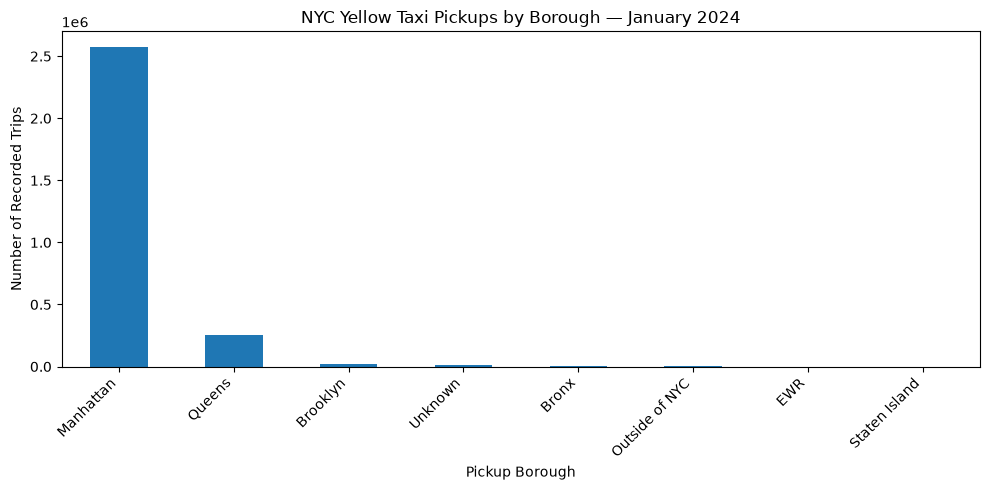

In [119]:

import matplotlib.pyplot as plt

# Create a bar chart
pickup_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("NYC Yellow Taxi Pickups by Borough — January 2024")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Recorded Trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [120]:
# Calculate January pickup counts and percentages by borough
borough_summary = pd.DataFrame({
    "Trip_Count": jan_borough_trips[
        "pickup_borough_report"
    ].value_counts()
})

# Calculate each borough's percentage of January pickups
borough_summary["Percentage"] = (
    borough_summary["Trip_Count"] /
    borough_summary["Trip_Count"].sum()
) * 100

# Display the summary table
display(borough_summary.round(2))

,Trip_Count,Percentage
pickup_borough_report,,
Manhattan,2571717,89.68
Queens,257500,8.98
Brooklyn,22240,0.78
Unknown,9613,0.34
Bronx,5740,0.20
Outside of NYC,687,0.02
EWR,49,0.00
Staten Island,45,0.00


In [121]:

# Count January 2024 taxi pickups by hour
hourly_trips = (
    jan_borough_trips["pickup_hour"]
    .value_counts()
    .sort_index()
)

# Display hourly pickup counts
display(hourly_trips)

# Verify the total
print("Total January pickups:", hourly_trips.sum())

# Identify the busiest hour
print("Busiest hour:", hourly_trips.idxmax())
print("Trips during busiest hour:", hourly_trips.max())


pickup_hour
0      75155
1      50429
2      34923
3      22916
4      15252
5      17483
6      39390
7      80803
8     113423
9     125519
10    135312
11    146634
12    159800
13    165185
14    177854
15    183823
16    184807
17    200141
18    206134
19    178667
20    155445
21    155804
22    138149
23    104543
Name: count, dtype: int64

Total January pickups: 2867591
Busiest hour: 18
Trips during busiest hour: 206134


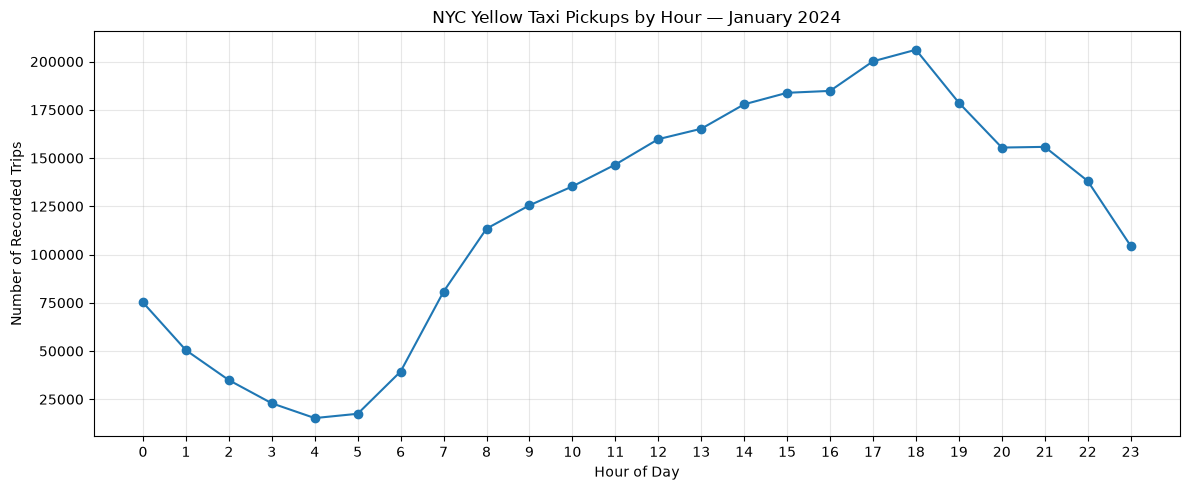

In [122]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_trips.index,
    hourly_trips.values,
    marker="o"
)

plt.title("NYC Yellow Taxi Pickups by Hour — January 2024")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Recorded Trips")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [123]:

# Extract day of week from pickup timestamp
df_with_zones["day_of_week"] = (
    df_with_zones["tpep_pickup_datetime"].dt.dayofweek
)

# Create a weekday/weekend category
df_with_zones["day_type"] = (
    df_with_zones["day_of_week"]
    .apply(lambda day: "Weekend" if day >= 5 else "Weekday")
)

# Display sample records
display(df_with_zones[[
    "tpep_pickup_datetime",
    "day_of_week",
    "day_type"
]].head())


,tpep_pickup_datetime,day_of_week,day_type
0,2024-01-01 00:57:55,0,Weekday
1,2024-01-01 00:03:00,0,Weekday
2,2024-01-01 00:17:06,0,Weekday
3,2024-01-01 00:36:38,0,Weekday
4,2024-01-01 00:46:51,0,Weekday


In [124]:

# Extract the calendar date
df_with_zones["pickup_date"] = (
    df_with_zones["tpep_pickup_datetime"].dt.date
)

# Restrict analysis to January 2024 pickup timestamps
jan_trips = df_with_zones[
    (df_with_zones["tpep_pickup_datetime"] >= "2024-01-01") &
    (df_with_zones["tpep_pickup_datetime"] < "2024-02-01")
].copy()

# Count trips by date, day type and hour
daily_hourly = (
    jan_trips
    .groupby(["pickup_date", "day_type", "pickup_hour"])
    .size()
    .reset_index(name="trip_count")
)

display(daily_hourly.head())


,pickup_date,day_type,pickup_hour,trip_count
0,2024-01-01,Weekday,0,6193
1,2024-01-01,Weekday,1,6678
2,2024-01-01,Weekday,2,5473
3,2024-01-01,Weekday,3,4372
4,2024-01-01,Weekday,4,2865


In [125]:

# Count distinct weekdays and weekend days in January
dates = pd.date_range("2024-01-01", "2024-01-31")
day_counts = {
    "Weekday": (dates.dayofweek < 5).sum(),
    "Weekend": (dates.dayofweek >= 5).sum()
}

# Sum pickups by day type and hour
hourly_comparison = (
    daily_hourly
    .groupby(["day_type", "pickup_hour"])["trip_count"]
    .sum()
    .unstack("day_type", fill_value=0)
    .reindex(range(24), fill_value=0)
)

# Convert totals into average trips per calendar day
for day_type in ["Weekday", "Weekend"]:
    hourly_comparison[day_type] = (
        hourly_comparison[day_type] / day_counts[day_type]
    )

display(hourly_comparison.round(0))


day_type,Weekday,Weekend
pickup_hour,,
0,1633.0,4699.0
1,918.0,3665.0
2,590.0,2670.0
3,431.0,1626.0
4,372.0,836.0
5,626.0,385.0
6,1485.0,654.0
7,3142.0,1066.0
8,4313.0,1777.0


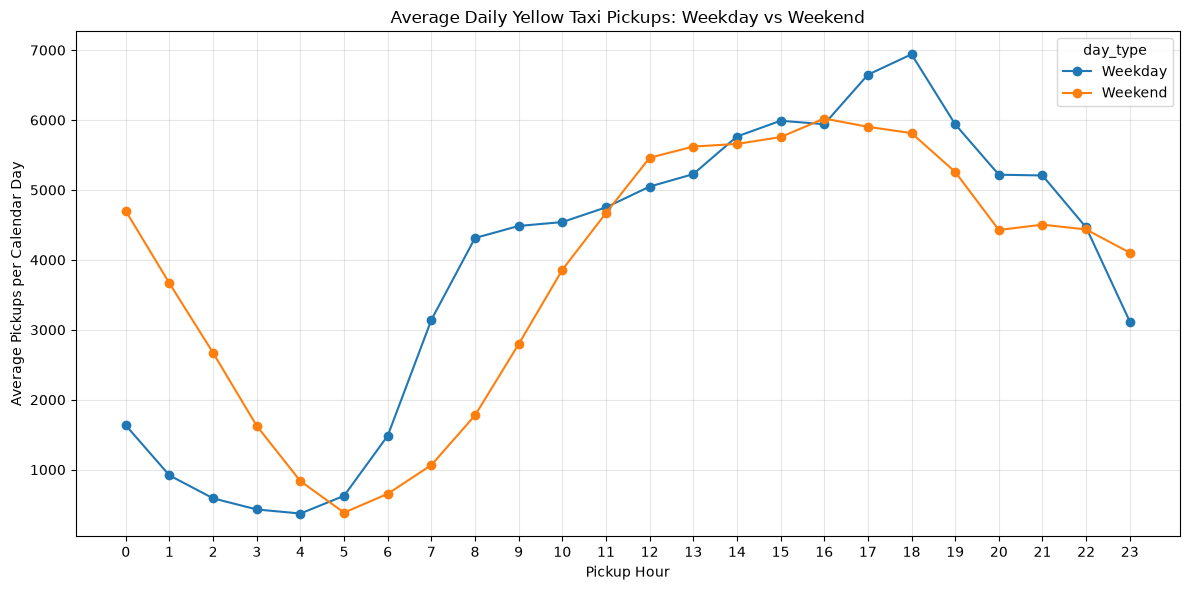

In [126]:

import matplotlib.pyplot as plt

hourly_comparison.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Average Daily Yellow Taxi Pickups: Weekday vs Weekend")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Pickups per Calendar Day")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [127]:

# Find the busiest hour for weekdays
weekday_peak_hour = hourly_comparison["Weekday"].idxmax()
weekday_peak_count = hourly_comparison["Weekday"].max()

# Find the busiest hour for weekends
weekend_peak_hour = hourly_comparison["Weekend"].idxmax()
weekend_peak_count = hourly_comparison["Weekend"].max()

print("Weekday peak hour:", weekday_peak_hour)
print("Average weekday pickups:", round(weekday_peak_count, 2))

print("Weekend peak hour:", weekend_peak_hour)
print("Average weekend pickups:", round(weekend_peak_count, 2))


Weekday peak hour: 18
Average weekday pickups: 6940.43
Weekend peak hour: 16
Average weekend pickups: 6021.62


In [128]:

# Calculate trip duration statistics for each pickup hour
hourly_duration = (
    jan_trips
    .groupby("pickup_hour")
    .agg(
        Trip_Count=("trip_duration_min", "size"),
        Average_Duration=("trip_duration_min", "mean"),
        Median_Duration=("trip_duration_min", "median")
    )
    .reset_index()
)

# Display the results
display(hourly_duration.round(2))


,pickup_hour,Trip_Count,Average_Duration,Median_Duration
0,0,75155,13.73,11.25
1,1,50429,12.69,10.57
2,2,34923,12.01,10.10
3,3,22916,12.16,10.07
4,4,15252,13.99,11.32
5,5,17483,16.52,11.18
6,6,39390,15.74,9.83
7,7,80803,15.00,10.42
8,8,113423,15.18,11.45
9,9,125519,15.12,11.75


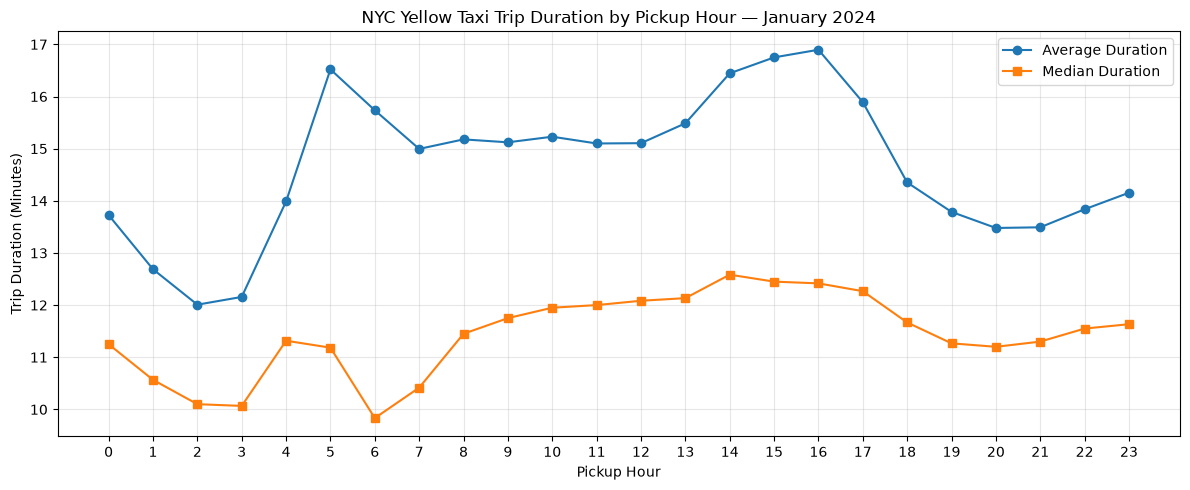

In [129]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_duration["pickup_hour"],
    hourly_duration["Average_Duration"],
    marker="o",
    label="Average Duration"
)

plt.plot(
    hourly_duration["pickup_hour"],
    hourly_duration["Median_Duration"],
    marker="s",
    label="Median Duration"
)

plt.title("NYC Yellow Taxi Trip Duration by Pickup Hour — January 2024")
plt.xlabel("Pickup Hour")
plt.ylabel("Trip Duration (Minutes)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [130]:

# Find the hour with the highest average trip duration
longest_avg_hour = hourly_duration.loc[
    hourly_duration["Average_Duration"].idxmax()
]

print("Hour:", int(longest_avg_hour["pickup_hour"]))

print(
    "Average duration:",
    round(longest_avg_hour["Average_Duration"], 2),
    "minutes"
)

print(
    "Median duration:",
    round(longest_avg_hour["Median_Duration"], 2),
    "minutes"
)


Hour: 16
Average duration: 16.9 minutes
Median duration: 12.42 minutes


In [131]:

# Calculate average trip distance by pickup hour
hourly_distance = (
    jan_trips
    .groupby("pickup_hour")
    .agg(
        Trip_Count=("trip_distance", "size"),
        Average_Distance=("trip_distance", "mean"),
        Median_Distance=("trip_distance", "median")
    )
    .reset_index()
)

display(hourly_distance.round(2))


,pickup_hour,Trip_Count,Average_Distance,Median_Distance
0,0,75155,3.85,2.14
1,1,50429,3.26,2.00
2,2,34923,3.04,1.97
3,3,22916,3.52,2.10
4,4,15252,4.86,2.70
5,5,17483,6.23,2.75
6,6,39390,4.73,2.12
7,7,80803,3.56,1.80
8,8,113423,3.06,1.64
9,9,125519,3.05,1.60


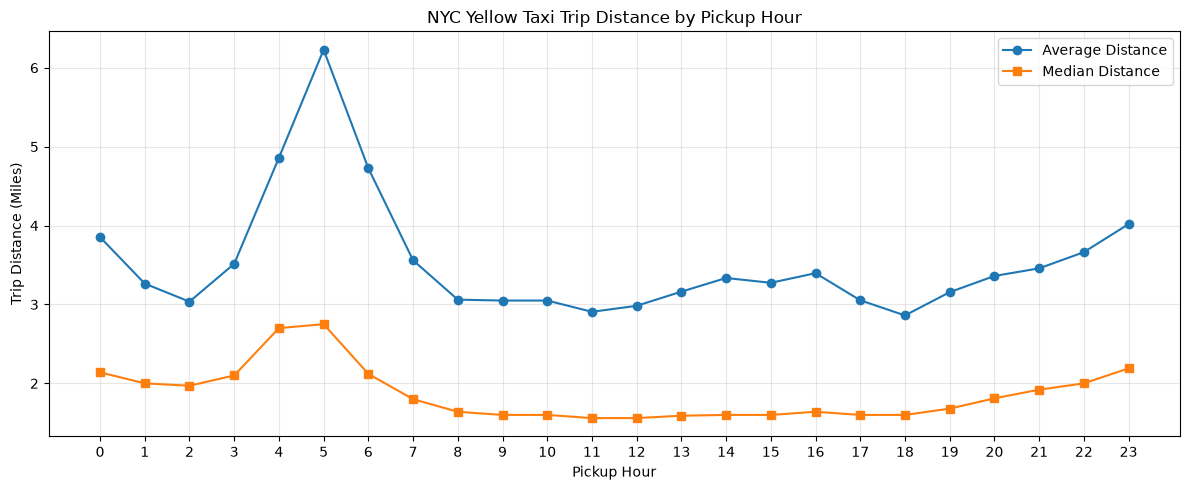

In [132]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_distance["pickup_hour"],
    hourly_distance["Average_Distance"],
    marker="o",
    label="Average Distance"
)

plt.plot(
    hourly_distance["pickup_hour"],
    hourly_distance["Median_Distance"],
    marker="s",
    label="Median Distance"
)

plt.title("NYC Yellow Taxi Trip Distance by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Trip Distance (Miles)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [133]:

# Find the pickup hour with the highest average distance
longest_distance_hour = hourly_distance.loc[
    hourly_distance["Average_Distance"].idxmax()
]

print("Pickup hour:", int(longest_distance_hour["pickup_hour"]))

print(
    "Average distance:",
    round(longest_distance_hour["Average_Distance"], 2),
    "miles"
)

print(
    "Median distance:",
    round(longest_distance_hour["Median_Distance"], 2),
    "miles"
)


Pickup hour: 5
Average distance: 6.23 miles
Median distance: 2.75 miles


In [134]:

import pandas as pd

# Group journeys into distance ranges
jan_trips = jan_trips.copy()

jan_trips["distance_category"] = pd.cut(
    jan_trips["trip_distance"],
    bins=[0, 2, 5, 10, 20, 100],
    labels=["0-2", "2-5", "5-10", "10-20", "20-100"],
    include_lowest=True
)

# Display sample records
display(jan_trips[[
    "trip_distance",
    "distance_category",
    "trip_duration_min"
]].head())


,trip_distance,distance_category,trip_duration_min
0,1.72,0-2,19.800000
1,1.80,0-2,6.600000
2,4.70,2-5,17.916667
3,1.40,0-2,8.300000
4,0.80,0-2,6.100000


In [135]:

# Calculate trip duration by distance category
distance_duration_summary = (
    jan_trips
    .groupby("distance_category", observed=True)
    .agg(
        Trip_Count=("trip_duration_min", "size"),
        Average_Duration=("trip_duration_min", "mean"),
        Median_Duration=("trip_duration_min", "median")
    )
    .reset_index()
)

display(distance_duration_summary.round(2))


,distance_category,Trip_Count,Average_Duration,Median_Duration
0,0-2,1662587,8.72,8.02
1,2-5,749959,17.71,16.62
2,5-10,230390,25.71,23.75
3,10-20,195849,39.60,36.45
4,20-100,28806,49.79,46.03


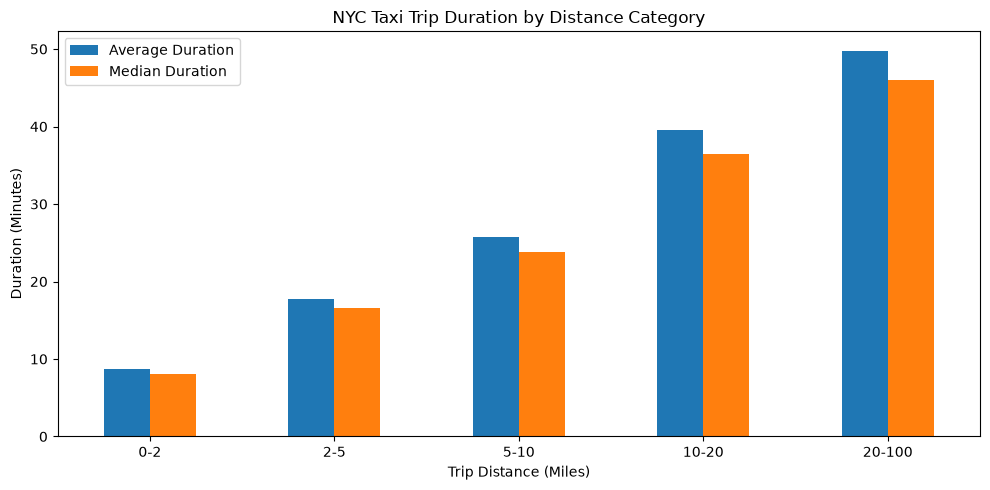

In [136]:

import matplotlib.pyplot as plt

distance_duration_summary.plot(
    x="distance_category",
    y=["Average_Duration", "Median_Duration"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("NYC Taxi Trip Duration by Distance Category")
plt.xlabel("Trip Distance (Miles)")
plt.ylabel("Duration (Minutes)")
plt.xticks(rotation=0)
plt.legend(["Average Duration", "Median Duration"])
plt.tight_layout()
plt.show()


In [137]:

# Compare the number of records
print("Standard dataset:", len(df_standard))
print("January dataset:", len(jan_trips))

# Check records without a distance category
print(
    "Missing distance categories:",
    jan_trips["distance_category"].isna().sum()
)

# Verify category totals
print(
    "Total grouped trips:",
    distance_duration_summary["Trip_Count"].sum()
)


Standard dataset: 2867608
January dataset: 2867591
Missing distance categories: 0
Total grouped trips: 2867591


In [138]:

# Identify trips outside January 2024
outside_january = df_with_zones[
    (df_with_zones["tpep_pickup_datetime"] < "2024-01-01") |
    (df_with_zones["tpep_pickup_datetime"] >= "2024-02-01")
]

print("Trips outside January:", len(outside_january))

# View their pickup dates
print(
    outside_january["tpep_pickup_datetime"]
    .dt.date
    .value_counts()
    .sort_index()
)


Trips outside January: 17
tpep_pickup_datetime
2002-12-31     1
2009-01-01     3
2023-12-31    10
2024-02-01     3
Name: count, dtype: int64


In [139]:

# Final dataset verification

print("Original records:", len(df))
print("Standard trip records:", len(df_standard))
print("January analysis records:", len(jan_trips))
print("Records after location joins:", len(df_with_zones))

print("\nMissing pickup borough labels:",
      df_with_zones["pickup_borough_report"].isna().sum())

print("Missing drop-off borough labels:",
      df_with_zones["dropoff_borough_report"].isna().sum())


Original records: 2964624
Standard trip records: 2867608
January analysis records: 2867591
Records after location joins: 2867608

Missing pickup borough labels: 0
Missing drop-off borough labels: 0


In [140]:
# Create the final dataset for SQL analysis
df_final = jan_trips.copy()

# Verify the final dataset
print("Final records:", len(df_final))
print("Final columns:", len(df_final.columns))

display(df_final.head())

Final records: 2867591
Final columns: 37


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,LocationID_dropoff,dropoff_borough,dropoff_zone,pickup_borough_report,dropoff_borough_report,pickup_hour,day_of_week,day_type,pickup_date,distance_category
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,...,79,Manhattan,East Village,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,...,236,Manhattan,Upper East Side North,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,...,79,Manhattan,East Village,Manhattan,Manhattan,0,0,Weekday,2024-01-01,2-5
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,...,211,Manhattan,SoHo,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,...,148,Manhattan,Lower East Side,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2


## 6. Preparing Data for SQL Analysis

This section selects the relevant columns from the cleaned January 2024 taxi dataset for further analysis using SQL.

The selected fields support analysis of trip demand, pickup locations, travel duration, distance, fares and payment methods.

In [141]:

# Check available columns in our final dataset
print("Total columns:", len(df_final.columns))

for column in df_final.columns:
    print(column)


Total columns: 37
VendorID
tpep_pickup_datetime
tpep_dropoff_datetime
passenger_count
trip_distance
RatecodeID
store_and_fwd_flag
PULocationID
DOLocationID
payment_type
fare_amount
extra
mta_tax
tip_amount
tolls_amount
improvement_surcharge
total_amount
congestion_surcharge
Airport_fee
trip_duration_min
valid_duration
average_speed_mph
valid_distance
fare_review_flag
LocationID
pickup_borough
pickup_zone
LocationID_dropoff
dropoff_borough
dropoff_zone
pickup_borough_report
dropoff_borough_report
pickup_hour
day_of_week
day_type
pickup_date
distance_category


In [143]:

# Select the columns needed for SQL analysis
sql_columns = [
    "VendorID",
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "PULocationID",
    "DOLocationID",
    "payment_type",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "trip_duration_min",
    "pickup_borough_report",
    "dropoff_borough_report",
    "pickup_hour",
    "day_of_week",
    "day_type",
    "pickup_date",
    "distance_category"
]

# Create a smaller dataset containing only these columns
df_sql = df_final[sql_columns].copy()

# Check the new dataset
print("SQL dataset rows:", len(df_sql))
print("SQL dataset columns:", len(df_sql.columns))

display(df_sql.head())


SQL dataset rows: 2867591
SQL dataset columns: 19


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount,trip_duration_min,pickup_borough_report,dropoff_borough_report,pickup_hour,day_of_week,day_type,pickup_date,distance_category
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,186,79,2,17.7,0.00,22.70,19.800000,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,140,236,1,10.0,3.75,18.75,6.600000,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,236,79,1,23.3,3.00,31.30,17.916667,Manhattan,Manhattan,0,0,Weekday,2024-01-01,2-5
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,79,211,1,10.0,2.00,17.00,8.300000,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,211,148,1,7.9,3.20,16.10,6.100000,Manhattan,Manhattan,0,0,Weekday,2024-01-01,0-2


In [ ]:

# Define where to save the SQL dataset
output_path = data_folder / "nyc_taxi_cleaned_jan2024.csv"

# Export the dataset to CSV
df_sql.to_csv(output_path, index=False)

# Verify that the file was created
print("CSV exported successfully!")
print("File location:", output_path)
print("File size (MB):", round(output_path.stat().st_size / (1024 * 1024), 2))
print("Total exported rows:", len(df_sql))
print("Total exported columns:", len(df_sql.columns))


CSV exported successfully!
File location: e:\Data Analyst Projects\NYC-Taxi-Analytics\Data\nyc_taxi_cleaned_jan2024.csv
File size (MB): 376.48


## Preliminary Business Findings

### 1. Peak Taxi Demand
6 PM recorded the highest pickup volume, with 206,134 trips.

### 2. Weekday vs Weekend Demand
Weekday pickup demand peaked at 6 PM, while weekend demand peaked at 4 PM.

### 3. Trip Duration
Trips starting at 4 PM had the longest average duration, at 16.90 minutes.

### 4. Trip Distance
Trips starting at 5 AM had the highest average distance, at 6.23 miles.

### 5. Distance and Duration Relationship
Average trip duration increased across the five distance categories analysed.

### Business Implications
These findings could help taxi operators investigate how driver availability aligns with demand at different times and how trip characteristics affect operational planning.

### Limitations
The findings are based on filtered January 2024 NYC Yellow Taxi records, not all transport trips in New York City.

Duration, distance and financial filters exclude certain records. The observed patterns do not establish the causes of demand or travel-time differences.